# 京都大学 2026 理系 第6問 — Julia + Wolfram Engine で解く

## 問題

$n$ は $3$ 以上の整数とする。$1$ から $n$ までの番号が書かれた $n$ 枚の札が袋に入っている。ただし，同じ番号が書かれた札はないとする。この袋から 3 枚の札を同時に取り出し，一番大きな番号を $X$ とする。$X$ の期待値を求めよ。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。

In [1]:
include("wolfram_common.jl");     # MathLink の読み込みと，共通の関数（表示・変換）

## 1. $P(X = n)$ を求める

$n$ 枚から 3 枚を取り出す方法は全部で ${}_n\mathrm{C}_3$ 通りで，どれも同様に確からしい。

$X = n$ となるのは，**番号 $n$ の札を取り出し，残り 2 枚を $1$ から $n-1$ までの $n-1$ 枚から選ぶ**ときなので ${}_{n-1}\mathrm{C}_2$ 通り。したがって

$$P(X = n) = \frac{{}_{n-1}\mathrm{C}_2}{{}_n\mathrm{C}_3}$$

これを Wolfram で整理します（`Binomial` が二項係数，`FunctionExpand` で階乗の形に展開してから `Simplify`）。

In [2]:
total = W`Binomial[n, 3]`          # 全部の取り出し方
favor = W`Binomial[n - 1, 2]`      # X = n となる取り出し方

showtex("{}_n\\mathrm{C}_3 = " * tex(weval(W"Factor"(W"FunctionExpand"(total)))) *
        ",\\qquad {}_{n-1}\\mathrm{C}_2 = " * tex(weval(W"Factor"(W"FunctionExpand"(favor)))))

pnw = weval(W"Simplify"(W"FunctionExpand"(W"Divide"(favor, total))))
showtex("P(X = n) = " * tex(pnw))

$P(X = n) = \dfrac{3}{n}$ です。「3 枚の中に番号 $n$ の札が入っている確率」と考えても，$n$ 枚のうち 3 枚を取るので $\dfrac{3}{n}$ と分かります。

### 検算 1：Julia ですべての取り出し方を数える

小さい $n$ で，3 枚の組をすべて書き出して，最大の番号が $n$ になる割合を数えます。Wolfram の式を Julia の関数にしたもの（`pn`）と比べます。

In [3]:
pn = to_function(pnw, :n)                                                   # Wolfram の式 → Julia の関数

triples(n) = [(a, b, c) for a in 1:n for b in a+1:n for c in b+1:n]         # 3 枚の組（a < b < c）すべて

for n in 3:10
    ts = triples(n)
    cnt = count(t -> maximum(t) == n, ts)
    println("n = ", lpad(n, 2), "  全部で ", lpad(length(ts), 3), " 通り，X = n は ", lpad(cnt, 2), " 通り → ",
            rpad(cnt // length(ts), 5), "  式の値 3/n = ", pn(n))
end

n =  3  全部で   1 通り，X = n は  1 通り → 1//1   式の値 3/n = 1
n =  4  全部で   4 通り，X = n は  3 通り → 3//4   式の値 3/n = 3//4
n =  5  全部で  10 通り，X = n は  6 通り → 3//5   式の値 3/n = 3//5
n =  6  全部で  20 通り，X = n は 10 通り → 1//2   式の値 3/n = 1//2
n =  7  全部で  35 通り，X = n は 15 通り → 3//7   式の値 3/n = 3//7
n =  8  全部で  56 通り，X = n は 21 通り → 3//8   式の値 3/n = 3//8
n =  9  全部で  84 通り，X = n は 28 通り → 1//3   式の値 3/n = 1//3
n = 10  全部で 120 通り，X = n は 36 通り → 3//10  式の値 3/n = 3//10


### 検算 2：実際に取り出してみる（シミュレーション）

$n = 10$ として，3 枚を取り出す実験を 100 万回くり返し，$X = 10$ となった割合を調べます。

In [4]:
using Random
Random.seed!(2026)

# 1 ～ n から 3 枚を同時に取り出したときの最大の番号
function drawmax(n)
    a = rand(1:n)
    b = rand(1:n); while b == a; b = rand(1:n); end
    c = rand(1:n); while c == a || c == b; c = rand(1:n); end
    max(a, b, c)
end

n, trials = 10, 1_000_000
freq = count(_ -> drawmax(n) == n, 1:trials) / trials
println("実験での割合 = ", freq, "   式の値 3/n = ", float(pn(n)))

実験での割合 = 0.299909   式の値 3/n = 0.3


## 2. 期待値を求める

### $P(X = k)$

1 節と同じ考え方で，$X = k$ となるのは**番号 $k$ の札を取り出し，残り 2 枚を $1$ から $k-1$ までの $k-1$ 枚から選ぶ**ときなので

$$P(X = k) = \frac{{}_{k-1}\mathrm{C}_2}{{}_n\mathrm{C}_3}\qquad(k = 3,\ 4,\ \dots,\ n)$$

（$X$ は 3 枚のうち最大の番号なので，$3$ 以上です。）

In [5]:
pkw = weval(W`Factor[FunctionExpand[Binomial[k - 1, 2]/Binomial[n, 3]]]`)
showtex("P(X = k) = " * tex(pkw))

確率の合計が $1$ になることを，Wolfram の `Sum` で確かめます。

In [6]:
tot = weval(W"Simplify"(W"Sum"(pkw, W`{k, 3, n}`)))
showtex("\\sum_{k=3}^{n} P(X = k) = " * tex(tot))

### 期待値 $E(X) = \displaystyle\sum_{k=3}^{n} k\,P(X = k)$

In [7]:
Ew = weval(W"Factor"(W"Sum"(W"Times"(W"k", pkw), W`{k, 3, n}`)))
showtex("E(X) = \\sum_{k=3}^{n} k \\cdot " * tex(pkw) * " = " * tex(Ew))

### 手計算ではどうするか

$k \cdot {}_{k-1}\mathrm{C}_2 = 3\,{}_k\mathrm{C}_3$ と，$\displaystyle\sum_{k=3}^{n} {}_k\mathrm{C}_3 = {}_{n+1}\mathrm{C}_4$ を使うと，

$$E(X) = \frac{1}{{}_n\mathrm{C}_3}\sum_{k=3}^{n} k\cdot{}_{k-1}\mathrm{C}_2 = \frac{3}{{}_n\mathrm{C}_3}\sum_{k=3}^{n} {}_k\mathrm{C}_3 = \frac{3\,{}_{n+1}\mathrm{C}_4}{{}_n\mathrm{C}_3}$$

と計算できます。使った 2 つの等式と，最後の式を Wolfram で確かめます。

In [8]:
id1 = weval(W`FullSimplify[FunctionExpand[k Binomial[k - 1, 2] - 3 Binomial[k, 3]]]`)                 # 0 なら成り立つ
id2 = weval(W`FullSimplify[FunctionExpand[Sum[Binomial[k, 3], {k, 3, n}] - Binomial[n + 1, 4]]]`)      # 0 なら成り立つ
E2w = weval(W`Factor[FunctionExpand[3 Binomial[n + 1, 4]/Binomial[n, 3]]]`)

showtex("k\\cdot{}_{k-1}\\mathrm{C}_2 - 3\\,{}_k\\mathrm{C}_3 = " * tex(id1) *
        ",\\qquad \\sum_{k=3}^{n}{}_k\\mathrm{C}_3 - {}_{n+1}\\mathrm{C}_4 = " * tex(id2) *
        ",\\qquad \\frac{3\\,{}_{n+1}\\mathrm{C}_4}{{}_n\\mathrm{C}_3} = " * tex(E2w))

### 検算 1：Julia ですべての取り出し方から平均をとる

期待値の式を Julia の関数 `EX(n)` にして，3 枚の組すべてについての「最大の番号の平均」と比べます。

In [9]:
EX = to_function(Ew, :n)      # Wolfram の式 → Julia の関数

for n in 3:10
    ts = triples(n)
    avg = sum(maximum(t) for t in ts) // length(ts)
    println("n = ", lpad(n, 2), "  すべての組での平均 = ", rpad(avg, 6), "  式の値 3(n+1)/4 = ", EX(n))
end

n =  3  すべての組での平均 = 3//1    式の値 3(n+1)/4 = 3
n =  4  すべての組での平均 = 15//4   式の値 3(n+1)/4 = 15//4
n =  5  すべての組での平均 = 9//2    式の値 3(n+1)/4 = 9//2
n =  6  すべての組での平均 = 21//4   式の値 3(n+1)/4 = 21//4
n =  7  すべての組での平均 = 6//1    式の値 3(n+1)/4 = 6
n =  8  すべての組での平均 = 27//4   式の値 3(n+1)/4 = 27//4
n =  9  すべての組での平均 = 15//2   式の値 3(n+1)/4 = 15//2
n = 10  すべての組での平均 = 33//4   式の値 3(n+1)/4 = 33//4


### 検算 2：シミュレーションと分布のグラフ（$n = 10$）

1 節の `drawmax` で 100 万回取り出し，$X$ の平均と，$X = k$ となった割合を調べます。

実験での平均 = 8.248563   式の値 = 8.25


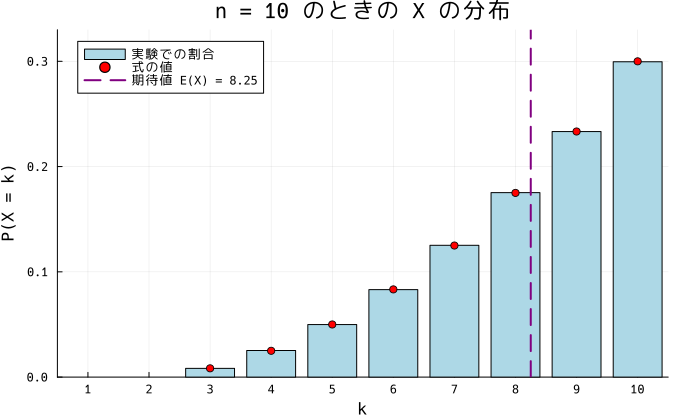

In [10]:
using Plots, Statistics
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

n, trials = 10, 1_000_000
xs = [drawmax(n) for _ in 1:trials]
println("実験での平均 = ", mean(xs), "   式の値 = ", float(EX(n)))

pk = to_function(pkw, :k, :n)      # P(X = k) を Julia の関数に
ks = 3:n
bar(ks, [count(==(k), xs) / trials for k in ks]; color=:lightblue, label="実験での割合", xlabel="k", ylabel="P(X = k)",
    xticks=1:n, xlims=(0.5, n + 0.5), ylims=(0, 0.33), legend=:topleft, size=(680, 420), title="n = 10 のときの X の分布")
scatter!(ks, float.(pk.(ks, n)); color=:red, label="式の値")
vline!([float(EX(n))]; color=:purple, ls=:dash, lw=2, label="期待値 E(X) = 8.25")

## 答え

$$E(X) = \frac{3(n+1)}{4}$$

$X$ は大きい番号に偏って分布し（$P(X = k)$ は $k$ の 2 次式で増える），期待値は最大の番号 $n$ の約 $\dfrac34$ になります。